# CoSTA for the heat equation (PDE): training, validation and testing

The canonical CoSTA benchmark. The **reference** system has a source term the modeler does not know about,

$$\frac{\partial T}{\partial t}=D\frac{\partial^2 T}{\partial x^2}+s(x,t;a),\qquad T(0,t)=T(1,t)=1,$$

while the **physics-based model (PBM)** omits $s$. CoSTA keeps the PBM's implicit solver and adds a learned
corrective source $\sigma_{\boldsymbol{\theta}}$ inside each step. We use the manufactured solution
$T^*(x,t;a)=1+a\sin(\pi x)e^{-t}$, so the reference is known exactly.

This notebook is the course's **complete worked protocol**. It follows one chain from reference data to a tested model:

1. **Partition** whole trajectories (amplitudes $a$) into training, validation and test sets *before* building any sample.
2. **Build labels** from consecutive reference states and the nominal solver.
3. **Train** the correction by supervised regression on the training trajectories only.
4. **Validate**: run recursive simulations on the validation trajectories at fixed checkpoints and keep the best checkpoint.
5. **Test**: freeze the selected model and run recursive simulations on held-out amplitudes. The reference is used only to score.

The prose narrates the **default** run. Change the values below and *Run All*; every figure, table and saved
result follows. Checks that quote the default numbers are skipped when the parameters differ from the defaults.

In [1]:
# ---- Parameters (edit these, then Run All) -------------------------------
SEED = 0                       # network initialization seed for the walkthrough
D = 0.5                        # diffusivity
N_X = 41                       # grid nodes on [0, 1]
T_END, N_T = 1.0, 50           # horizon and number of backward-Euler steps
# split of complete trajectories (amplitudes a), fixed before any tuning
A_TRAIN = [0.5, 1.0, 2.0, 2.5, 3.0]
A_VAL = [0.75, 1.75, 2.75]     # checkpoint selection only
A_TEST_INTERP = [1.25, 2.25]   # held out, inside the training amplitude range
A_TEST_EXTRAP = [0.35, 3.75, 4.25]  # held out, outside the training amplitude range
A_HISTORICAL = 1.5             # inspected in earlier versions of this notebook: diagnostic only
A_SHOW = 2.25                  # test case drawn in the field figure
FEATURES = 'stencil'           # 'stencil' = [T_{i-1}, T_i, T_{i+1}];  'stencil+xt' adds x_i and t_n
HIDDEN = [40, 40]
LR, MAX_STEPS = 2e-3, 3000     # Adam; learning rate halves every 2000 steps
VAL_EVERY = 100                # validation interval [steps]
PATIENCE = 10                  # stop after this many validations without improvement
MIN_REL_IMPROVEMENT = 0.01     # an improvement must beat the best by 1 %
RUN_ABLATION = True            # also train the other feature set (x5 seeds with the sweep)
RUN_SEED_SWEEP = True          # retrain for SWEEP_SEEDS (~1 min in total) and save the table
SWEEP_SEEDS = [0, 1, 2, 3, 4]
# --------------------------------------------------------------------------

DEFAULTS = dict(SEED=0, D=0.5, N_X=41, T_END=1.0, N_T=50, A_TRAIN=[0.5, 1.0, 2.0, 2.5, 3.0],
                A_VAL=[0.75, 1.75, 2.75], A_TEST_INTERP=[1.25, 2.25], A_TEST_EXTRAP=[0.35, 3.75, 4.25],
                FEATURES='stencil', HIDDEN=[40, 40], LR=2e-3, MAX_STEPS=3000, VAL_EVERY=100,
                PATIENCE=10, MIN_REL_IMPROVEMENT=0.01)
AT_DEFAULTS = all(globals()[k] == v for k, v in DEFAULTS.items())

### Setup and the backward-Euler heat solver

The discretized PBM uses a uniform grid of $N_x$ nodes on $[0,1]$ and $N_t$ backward-Euler steps to $T_{\text{end}}$,
with mesh ratio $r=D\,\Delta t/\Delta x^2$. The interior update is the tridiagonal solve

$$\mathbf{A}\,\mathbf{T}^{n+1}=\mathbf{T}^{n}+\Delta t\,\boldsymbol{\sigma}^{n}+\boldsymbol{b}_{\text{BC}},\qquad
\mathbf{A}=(1+2r)\mathbf{I}-r(\mathbf{E}_{+1}+\mathbf{E}_{-1}),$$

where the Dirichlet values enter through $\boldsymbol{b}_{\text{BC}}$. `step()` advances one implicit step with an optional
interior source. With a zero source it is exactly the PBM; CoSTA passes its learned correction through the same
argument, **without touching the solver**.

In [2]:
import sys, os, copy, json, time
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))  # -> python/
import numpy as np, torch, matplotlib.pyplot as plt
from pyutils import pinn_core as pc
from pyutils.pinn_core import MLP
from pyutils import save_dual, fg, muted
torch.set_default_dtype(torch.float64)
pc.set_plot_style()
FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)
DATA = os.path.abspath(os.path.join('..', 'data')); os.makedirs(DATA, exist_ok=True)
RESULTS_FILE = os.path.join(DATA, 'costa_heat_results.json')

x = np.linspace(0, 1, N_X); dx = x[1] - x[0]; dt = T_END / N_T
r = D * dt / dx**2
n_int = N_X - 2
A = (1 + 2*r)*np.eye(n_int) - r*np.eye(n_int, k=1) - r*np.eye(n_int, k=-1)
Ainv = np.linalg.inv(A)
T_LEFT = T_RIGHT = 1.0                       # Dirichlet values, known to the PBM

def step(Tn, src_int):
    """One backward-Euler step of the PBM with an interior source added."""
    b = Tn[1:-1] + dt*np.asarray(src_int, float)
    b = b.copy(); b[0] += r*T_LEFT; b[-1] += r*T_RIGHT
    Tnew = Tn.copy(); Tnew[1:-1] = Ainv @ b; Tnew[0] = T_LEFT; Tnew[-1] = T_RIGHT
    return Tnew

print(f'dx = {dx:.4f}, dt = {dt:.3f}, mesh ratio r = {r:.2f}')

dx = 0.0250, dt = 0.020, mesh ratio r = 16.00


## 1. The reference, and what the PBM is missing

The manufactured reference $T^*=1+a\sin(\pi x)e^{-t}$ satisfies the Dirichlet data for every $a$. Substituting it
into the PDE gives the missing source in closed form:

$$s=\partial_t T^*-D\,\partial_{xx}T^*=-(T^*-1)+D\pi^2(T^*-1)=(D\pi^2-1)\,(T^*-1).$$

For this family the missing physics is a **linear reaction term in the local temperature**, a heat source of
strength $D\pi^2-1\approx 3.93$ per unit excess temperature. The PBM omits it, so its field decays toward the
boundary value much faster than the reference.

In [3]:
def Tstar(a, t):
    return 1 + a*np.sin(np.pi*x)*np.exp(-t)

def reference(a):
    """Reference trajectory, shape (N_T+1, N_X)."""
    return np.array([Tstar(a, n*dt) for n in range(N_T + 1)])

def rollout(a, correction=None):
    """Recursive simulation from the exact initial field.

    Prediction uses only the initial field, the boundary values and the model's own
    previous state: the reference trajectory is never consulted here.
    """
    T = Tstar(a, 0.0); traj = [T.copy()]
    for n in range(N_T):
        src = np.zeros(n_int) if correction is None else correction(T, n*dt)
        T = step(T, src); traj.append(T.copy())
    return np.array(traj)

SIGMA_SLOPE = D*np.pi**2 - 1
pbm_hist = rollout(A_HISTORICAL); ref_hist = reference(A_HISTORICAL)
print(f'missing-source slope D*pi^2 - 1 = {SIGMA_SLOPE:.3f}')
print(f'PBM at the historical a = {A_HISTORICAL}: final-time max error '
      f'{np.abs(pbm_hist[-1] - ref_hist[-1]).max():.3f}, final peak {pbm_hist[-1].max():.3f} '
      f'vs reference {ref_hist[-1].max():.3f}')

missing-source slope D*pi^2 - 1 = 3.935
PBM at the historical a = 1.5: final-time max error 0.538, final peak 1.014 vs reference 1.552


Starting from the non-flat exact initial field, the PBM loses the source that sustains the arch and relaxes almost
to the boundary value $T\equiv1$, while the reference still peaks well above it. The error is model-form bias,
not a discretization artifact: the grid and time step are the same for both.

## 2. Partition whole trajectories first

A **case** is one complete trajectory, identified by its amplitude $a$. Cases are assigned to roles before any
sample is extracted, so every stencil and time level from a trajectory stays in that trajectory's role. Splitting
rows at random would leak: neighbouring nodes and steps of one trajectory are near-copies of each other.

| Role | Purpose |
|---|---|
| training | fit the network weights and the normalization statistics |
| validation | choose the checkpoint (and, in general, hyperparameters) |
| test, interpolation | final score inside the training amplitude range |
| test, extrapolation | final score outside the training amplitude range |
| historical | the $a=1.5$ case shown in earlier versions; a diagnostic, never used for decisions |

train        a = [0.5, 1.0, 2.0, 2.5, 3.0]
val          a = [0.75, 1.75, 2.75]
test_interp  a = [1.25, 2.25]
test_extrap  a = [0.35, 3.75, 4.25]
historical   a = [1.5]


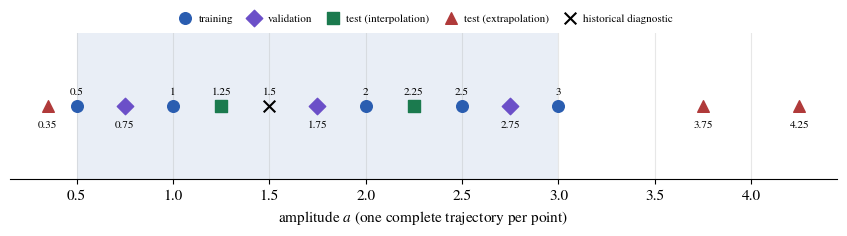

In [4]:
SPLIT = {'train': A_TRAIN, 'val': A_VAL, 'test_interp': A_TEST_INTERP,
         'test_extrap': A_TEST_EXTRAP, 'historical': [A_HISTORICAL]}
roles = list(SPLIT)
for i, ri in enumerate(roles):
    for rj in roles[i+1:]:
        overlap = set(SPLIT[ri]) & set(SPLIT[rj])
        assert not overlap, f'{ri} and {rj} share cases {overlap}'
lo_tr, hi_tr = min(A_TRAIN), max(A_TRAIN)
assert all(lo_tr < a < hi_tr for a in A_TEST_INTERP), 'interpolation cases must lie inside the training range'
assert all(a < lo_tr or a > hi_tr for a in A_TEST_EXTRAP), 'extrapolation cases must lie outside it'
MANIFEST = {role: [dict(case=f'{role}-{k}', a=a, T0='1 + a sin(pi x)', boundary=[T_LEFT, T_RIGHT],
                        horizon=T_END, n_steps=N_T, n_x=N_X) for k, a in enumerate(amps)]
            for role, amps in SPLIT.items()}
for role, amps in SPLIT.items():
    print(f'{role:12s} a = {amps}')

ROLE_STYLE = {'train': ('C0', 'o'), 'val': ('C4', 'D'), 'test_interp': ('C2', 's'),
              'test_extrap': ('C3', '^'), 'historical': (None, 'x')}
ROLE_LABEL = {'train': 'training', 'val': 'validation', 'test_interp': 'test (interpolation)',
              'test_extrap': 'test (extrapolation)', 'historical': 'historical diagnostic'}

def plot_costa_heat_split():
    fig, ax = plt.subplots(figsize=(8.6, 2.5))
    ax.axvspan(lo_tr, hi_tr, color='C0', alpha=0.10, lw=0)
    for k, (role, amps) in enumerate(SPLIT.items()):
        c, m = ROLE_STYLE[role]; c = c or fg()
        ax.scatter(amps, np.zeros(len(amps)), s=70, marker=m, color=c, label=ROLE_LABEL[role], zorder=3)
        for j, a in enumerate(sorted(amps)):
            ax.annotate(f'{a:g}', (a, 0), xytext=(0, 9 if k % 2 == 0 else -15), textcoords='offset points',
                        ha='center', fontsize=8)
    ax.set_yticks([]); ax.set_ylim(-0.5, 0.5); ax.set_xlabel('amplitude $a$ (one complete trajectory per point)')
    for s in ['left', 'right', 'top']:
        ax.spines[s].set_visible(False)
    ax.legend(ncol=5, fontsize=8, loc='lower center', bbox_to_anchor=(0.5, 1.0), frameon=False,
              handletextpad=0.2, columnspacing=0.9)
    plt.tight_layout()

save_dual(plot_costa_heat_split, 'costa_heat_split', FIG)
plt.show()

Five training trajectories, three for validation, and five for the final test. Two test cases lie inside the training
range and three outside it. The assertions check that no amplitude appears in two roles.

Note that "outside the amplitude range" is not the same as "outside the network's input range". The network sees
local temperatures, not $a$. A small amplitude such as $a=0.35$ produces temperatures between $1$ and $1.35$, which
the training trajectories already visit as they decay. Section 6 returns to this.

## 3. Labels: the exact discrete corrective source

Use the PBM's own discrete operator. For a reference step from $\mathbf T^{*,n}$ to $\mathbf T^{*,n+1}$, the
correction that makes the PBM step land exactly on the reference is

$$\sigma^{*,n}_i=\frac{T^{*,n+1}_i-T^{*,n}_i}{\Delta t}-D\,\frac{T^{*,n+1}_{i+1}-2T^{*,n+1}_i+T^{*,n+1}_{i-1}}{\Delta x^2}.$$

This is a *discrete* quantity. It contains the missing physics $s$ plus whatever temporal and spatial
truncation error the backward-Euler scheme makes on this grid. It is the right label for CoSTA, but it is not by
itself an identified physical law.

The time levels matter:

* the **feature** vector is built from the state at time level $n$: $\boldsymbol{q}^n_i=[T^n_{i-1},T^n_i,T^n_{i+1}]$;
* the **label** needs the reference at level $n+1$, which is available when building the training set but
  **not** when predicting. At prediction time the network sees only the current, possibly imperfect, state.

In [5]:
def d2(T):
    return (T[:-2] - 2*T[1:-1] + T[2:]) / dx**2

def label(Tn, Tn1):
    """Exact discrete corrective source for the step Tn -> Tn1 (interior nodes)."""
    return (Tn1[1:-1] - Tn[1:-1])/dt - D*d2(Tn1)

def features(T, tn, kind=FEATURES):
    cols = [T[:-2], T[1:-1], T[2:]]
    if kind == 'stencil+xt':
        cols += [x[1:-1], np.full(n_int, tn)]
    return np.stack(cols, 1)

def dataset(amps, kind=FEATURES):
    """Feature rows at level n and labels from levels n, n+1, for whole trajectories."""
    F, Y = [], []
    for a in amps:
        R = reference(a)
        for n in range(N_T):
            F.append(features(R[n], n*dt, kind)); Y.append(label(R[n], R[n+1]))
    return np.vstack(F), np.concatenate(Y)[:, None]

# one worked sample: training case a = 1.0, time level n = 10, node i = 20
a0, n0, i0 = 1.0, 10, 20
R0 = reference(a0)
print(f'sample (a={a0}, n={n0}, i={i0}, x={x[i0]:.3f}, t_n={n0*dt:.2f})')
print('  features q =', np.round(features(R0[n0], n0*dt)[i0-1], 5))
print(f'  label sigma* = {label(R0[n0], R0[n0+1])[i0-1]:.5f}'
      f'   (continuous s at level n: {SIGMA_SLOPE*(R0[n0][i0]-1):.5f})')

# sanity check 1: the exact correction reproduces the reference step
worst = 0.0
for a in A_TRAIN + A_TEST_EXTRAP:
    R = reference(a)
    worst = max(worst, max(np.abs(step(R[n], label(R[n], R[n+1])) - R[n+1]).max() for n in range(N_T)))
print(f'exact correction, one step from the reference: max error {worst:.1e}')
assert worst < 1e-10
# sanity check 2: a zero correction is exactly the PBM
zero = lambda T, tn: np.zeros(n_int)
assert np.array_equal(rollout(A_HISTORICAL, zero), pbm_hist)
print('zero correction reproduces the PBM exactly')

sample (a=1.0, n=10, i=20, x=0.500, t_n=0.20)
  features q = [1.81621 1.81873 1.81621]
  label sigma* = 3.14764   (continuous s at level n: 3.22154)
exact correction, one step from the reference: max error 7.1e-15
zero correction reproduces the PBM exactly


The worked sample shows the whole learning problem in one row. Three temperatures at level $n$ form the input, and
one number that needs level $n+1$ forms the target. The label is close to, but not equal to, the continuous source
$s$; the difference is the scheme's truncation error, which the correction must absorb as well.

Two sanity checks pass:

* inserting the exact discrete correction into one solver step lands on the next reference state to round-off;
* a zero correction reproduces the PBM rollout bit for bit.

The second is the precise "fallback" property. Setting the correction to zero gives the nominal update **from the
current state**. It does not undo error that has already accumulated, and it says nothing about how far a nonzero
correction may move the solution.

Because $T^{*,n+1}-1=e^{-\Delta t}(T^{*,n}-1)$ for this family, the exact label is a *linear* function of the
stencil. A network is more than we need here, which makes this a clean benchmark: any remaining error comes from
training, data coverage and rollout feedback, not from a hard regression target.

## 4. Training with validation-based checkpoint selection

The normalization statistics are fitted on **training rows only** and then applied unchanged to validation and test
inputs. The network $\sigma_{\boldsymbol{\theta}}(\boldsymbol{q})$ is an MLP trained by full-batch Adam on the standardized correction MSE.

Every `VAL_EVERY` steps, without updating the weights, we record two validation measurements:

* the correction MSE on the validation trajectories' reference states (a regression diagnostic);
* the **rollout RMSE**: run each validation case recursively from its initial field, feeding back the model's own
  predictions, and average the temperature RMSE over the validation cases.

The checkpoint with the lowest validation rollout RMSE is kept. A non-finite rollout counts as $+\infty$. Training
stops early after `PATIENCE` validations without a 1 % improvement. The selected checkpoint is restored before testing.

In [6]:
def rmse(P, R):
    return float(np.sqrt(np.mean((P - R)**2))) if np.all(np.isfinite(P)) else float('inf')

REF = {a: reference(a) for role in SPLIT for a in SPLIT[role]}

class Correction:
    """A trained correction: network plus the training-set normalization."""
    def __init__(self, net, stats, kind):
        self.net, self.stats, self.kind = net, stats, kind
    def __call__(self, T, tn):
        Fm, Fs, Ym, Ys = self.stats
        with torch.no_grad():
            z = torch.tensor((features(T, tn, self.kind) - Fm) / Fs)
            return self.net(z).numpy().ravel()*Ys + Ym

def fit_costa(seed=SEED, kind=FEATURES, verbose=False):
    F, Y = dataset(A_TRAIN, kind); Fv, Yv = dataset(A_VAL, kind)
    Fm, Fs = F.mean(0), F.std(0); Ym, Ys = Y.mean(), Y.std()      # training rows only
    Ft, Yt = torch.tensor((F-Fm)/Fs), torch.tensor((Y-Ym)/Ys)
    Fvt, Yvt = torch.tensor((Fv-Fm)/Fs), torch.tensor((Yv-Ym)/Ys)
    torch.manual_seed(seed)
    net = MLP([F.shape[1], *HIDDEN, 1]); corr = Correction(net, (Fm, Fs, Ym, Ys), kind)
    opt = torch.optim.Adam(net.parameters(), lr=LR)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=2000, gamma=0.5)
    hist = dict(step=[], train_mse=[], val_mse=[], val_rollout=[])
    best, best_step, best_state, waited = np.inf, 0, None, 0
    for k in range(MAX_STEPS + 1):
        if k % VAL_EVERY == 0 or k == MAX_STEPS:
            with torch.no_grad():
                tr = ((net(Ft) - Yt)**2).mean().item(); va = ((net(Fvt) - Yvt)**2).mean().item()
            vr = float(np.mean([rmse(rollout(a, corr), REF[a]) for a in A_VAL]))
            for key, val in zip(hist, (k, tr, va, vr)):
                hist[key].append(val)
            if vr < best*(1 - MIN_REL_IMPROVEMENT):
                best, best_step, best_state, waited = vr, k, copy.deepcopy(net.state_dict()), 0
            else:
                waited += 1
            if verbose and k % 500 == 0:
                print(f'step {k:5d}  train mse {tr:.2e}  val mse {va:.2e}  val rollout RMSE {vr:.2e}')
            if waited >= PATIENCE or k == MAX_STEPS:
                break
        opt.zero_grad(); loss = ((net(Ft) - Yt)**2).mean(); loss.backward(); opt.step(); sched.step()
    net.load_state_dict(best_state)                       # restore the selected checkpoint
    net.eval()
    return corr, dict(hist=hist, best_step=best_step, best_val_rollout=best, stopped_at=k)

t0 = time.time()
costa, info = fit_costa(verbose=True)
hist = info['hist']
print(f"selected checkpoint: step {info['best_step']} (validation rollout RMSE "
      f"{info['best_val_rollout']:.2e}); training stopped at step {info['stopped_at']}; {time.time()-t0:.0f} s")

# evaluating the model must not change it
w_before = [p.detach().clone() for p in costa.net.parameters()]
_ = [rollout(a, costa) for a in A_VAL]
assert all(torch.equal(p, q) for p, q in zip(w_before, costa.net.parameters()))

step     0  train mse 8.20e-01  val mse 6.91e-01  val rollout RMSE 2.41e-01


step   500  train mse 3.04e-04  val mse 1.55e-04  val rollout RMSE 2.90e-03


step  1000  train mse 6.57e-05  val mse 2.76e-05  val rollout RMSE 1.03e-03


step  1500  train mse 3.32e-05  val mse 1.78e-05  val rollout RMSE 1.18e-03


step  2000  train mse 2.25e-05  val mse 1.33e-05  val rollout RMSE 1.07e-03
selected checkpoint: step 1000 (validation rollout RMSE 1.03e-03); training stopped at step 2000; 7 s


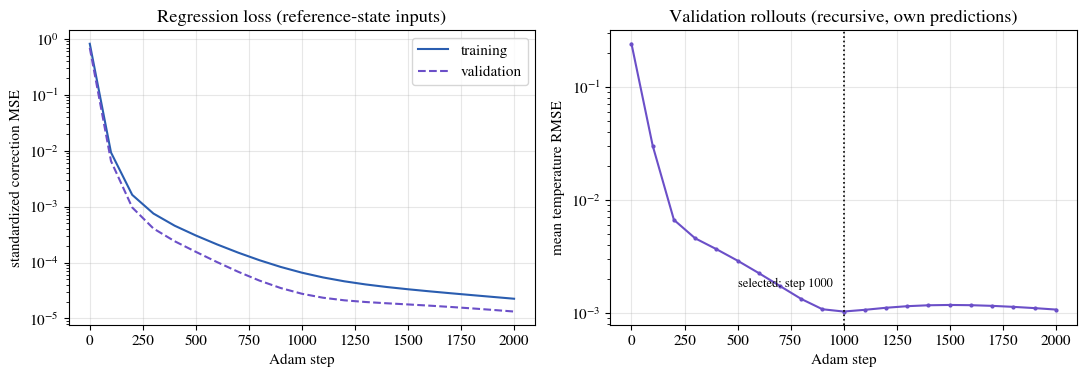

In [7]:
def plot_costa_heat_training():
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))
    ax[0].semilogy(hist['step'], hist['train_mse'], color='C0', label='training')
    ax[0].semilogy(hist['step'], hist['val_mse'], color='C4', ls='--', label='validation')
    ax[0].set(xlabel='Adam step', ylabel='standardized correction MSE', title='Regression loss (reference-state inputs)')
    ax[0].legend()
    ax[1].semilogy(hist['step'], hist['val_rollout'], color='C4', marker='.', ms=4)
    ax[1].axvline(info['best_step'], color=fg(), ls=':', lw=1.2)
    ax[1].annotate(f"selected: step {info['best_step']}", (info['best_step'], info['best_val_rollout']),
                   xytext=(-8, 18), textcoords='offset points', ha='right', fontsize=9)
    ax[1].set(xlabel='Adam step', ylabel='mean temperature RMSE',
              title='Validation rollouts (recursive, own predictions)')
    plt.tight_layout()

save_dual(plot_costa_heat_training, 'costa_heat_training', FIG)
plt.show()

Left: the training and validation correction losses fall together, so the regression generalizes to the
validation trajectories' reference states. Right: the quantity we actually care about, the error of recursive
validation simulations. It falls by two orders of magnitude in the first thousand steps and then fluctuates around
$10^{-3}$, while the regression losses keep creeping down. Early stopping ends the run once ten validations in a row
fail to improve on the best by 1 %. The marked checkpoint is the one used below.

The two panels measure different things. A small correction MSE on reference states does not guarantee a small
rollout error: in a rollout the network is fed its own slightly wrong states, and small errors can accumulate.
That is why the selection metric is the rollout.

## 5. Testing: frozen model, recursive simulation, held-out cases

The weights, normalization and solver are now frozen. Each test case starts from its initial field and boundary
values; at every step the network sees the state CoSTA itself predicted. The reference trajectory is used **only
after** the rollout, to score it. We report three metrics, each labelled separately:

* **RMSE** over all nodes and time levels of the rollout;
* **final-time max**: $\max_i|T_i^{N_t}-T_i^{*,N_t}|$ at the last step;
* **rollout max**: $\max_{n,i}|T^n_i-T^{*,n}_i|$ over the whole rollout.

In [8]:
def metrics(P, R):
    if not np.all(np.isfinite(P)):
        return dict(rmse=float('inf'), final_max=float('inf'), rollout_max=float('inf'))
    return dict(rmse=rmse(P, R), final_max=float(np.abs(P[-1]-R[-1]).max()),
                rollout_max=float(np.abs(P-R).max()))

def evaluate(corr):
    rows = []
    for role in ['train', 'val', 'test_interp', 'test_extrap', 'historical']:
        for a in SPLIT[role]:
            rows.append(dict(role=role, a=a, pbm=metrics(rollout(a), REF[a]),
                             costa=metrics(rollout(a, corr), REF[a])))
    return rows

rows = evaluate(costa)
print(f"{'role':12s} {'a':>5s} | {'PBM RMSE':>9s} {'CoSTA RMSE':>10s} | {'CoSTA final max':>15s} {'CoSTA rollout max':>17s}")
for rw in rows:
    print(f"{rw['role']:12s} {rw['a']:5.2f} | {rw['pbm']['rmse']:9.2e} {rw['costa']['rmse']:10.2e} | "
          f"{rw['costa']['final_max']:15.2e} {rw['costa']['rollout_max']:17.2e}")

role             a |  PBM RMSE CoSTA RMSE | CoSTA final max CoSTA rollout max
train         0.50 |  1.51e-01   1.31e-03 |        3.01e-03          3.01e-03
train         1.00 |  3.02e-01   8.35e-04 |        1.64e-04          1.83e-03
train         2.00 |  6.04e-01   5.42e-04 |        1.46e-03          1.46e-03
train         2.50 |  7.54e-01   2.20e-03 |        2.36e-03          5.55e-03
train         3.00 |  9.05e-01   2.81e-03 |        1.94e-03          9.69e-03
val           0.75 |  2.26e-01   5.97e-04 |        1.89e-03          1.89e-03
val           1.75 |  5.28e-01   7.28e-04 |        1.32e-03          1.88e-03
val           2.75 |  8.30e-01   1.76e-03 |        1.47e-03          4.76e-03
test_interp   1.25 |  3.77e-01   1.03e-03 |        1.20e-03          2.18e-03
test_interp   2.25 |  6.79e-01   1.29e-03 |        2.00e-03          3.69e-03
test_extrap   0.35 |  1.06e-01   1.42e-03 |        2.96e-03          2.96e-03
test_extrap   3.75 |  1.13e+00   4.00e-02 |        3.67e-02     

Read the table by role.

* **Training** rows are reconstructions of trajectories the network was fitted on. They show the fit, not generalization.
* **Validation** rows were used to choose the checkpoint, so they are slightly optimistic as well.
* The **test** rows are the honest numbers. On the interpolation cases CoSTA's rollout RMSE is more than two orders of
  magnitude below the PBM's (a factor of roughly 350 to 500).
* On the extrapolation cases the picture splits. $a=0.35$ behaves like an interpolation case, because its
  temperatures lie inside the visited range. $a=3.75$ and $4.25$ are clearly worse than the in-range cases, yet still
  well below the PBM.

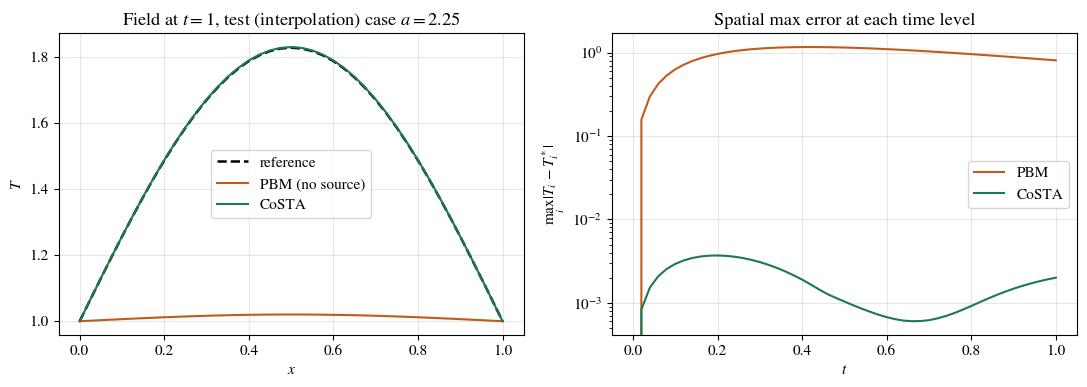

In [9]:
pbm_show, costa_show, ref_show = rollout(A_SHOW), rollout(A_SHOW, costa), REF[A_SHOW]
role_show = next(role for role, amps in SPLIT.items() if A_SHOW in amps)
err_pbm_t = np.abs(pbm_show - ref_show).max(1); err_costa_t = np.abs(costa_show - ref_show).max(1)
t_lev = np.arange(N_T + 1)*dt

def plot_costa_heat_correction():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.0))
    ax[0].plot(x, ref_show[-1], '--', color=fg(), lw=1.8, label='reference')
    ax[0].plot(x, pbm_show[-1], 'C1', label='PBM (no source)')
    ax[0].plot(x, costa_show[-1], 'C2', label='CoSTA')
    ax[0].legend(); ax[0].set(title=f'Field at $t={T_END:g}$, {ROLE_LABEL[role_show]} case $a={A_SHOW}$',
                              xlabel='$x$', ylabel='$T$')
    ax[1].semilogy(t_lev, err_pbm_t, 'C1', label='PBM')
    ax[1].semilogy(t_lev, err_costa_t, 'C2', label='CoSTA')
    ax[1].legend(); ax[1].set(title='Spatial max error at each time level', xlabel='$t$',
                              ylabel=r'$\max_i |T_i-T^*_i|$')
    plt.tight_layout()

save_dual(plot_costa_heat_correction, 'costa_heat_correction', FIG)
plt.show()

The left panel shows the held-out case at the final time. The PBM has decayed nearly flat, while CoSTA lies on the
reference arch. The right panel tracks the spatial maximum error at every time level of the recursive simulation.
The PBM error grows within a few steps and stays large. CoSTA's error stays small throughout, so feedback through
its own predictions does not cause drift over this horizon.

## 6. Across amplitudes, and what "extrapolation" means here

An exploratory sweep over $a\in[0.25,4.5]$ shows how the error changes with amplitude. It mixes roles: some
sweep points coincide with training or validation cases. So it is a diagnostic, and the test table above remains
the final result. Markers show the declared split cases.

The second figure explains the trend. It plots the learned correction against the local temperature for
every interior node and time level, coloured by split role, together with the continuous source
$s=(D\pi^2-1)(T-1)$.

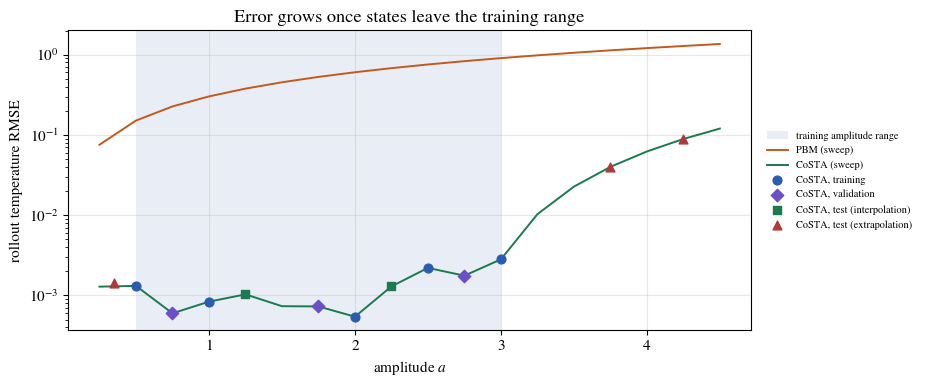

In [10]:
a_sweep = np.round(np.linspace(0.25, 4.5, 18), 3)
sweep_pbm = [rmse(rollout(a), reference(a)) for a in a_sweep]
sweep_costa = [rmse(rollout(a, costa), reference(a)) for a in a_sweep]
role_rows = {role: [rw for rw in rows if rw['role'] == role] for role in SPLIT}

def plot_costa_heat_generalization():
    fig, ax = plt.subplots(figsize=(9.4, 4.0))
    ax.axvspan(lo_tr, hi_tr, color='C0', alpha=0.10, lw=0, label='training amplitude range')
    ax.semilogy(a_sweep, sweep_pbm, '-', color='C1', lw=1.4, label='PBM (sweep)')
    ax.semilogy(a_sweep, sweep_costa, '-', color='C2', lw=1.4, label='CoSTA (sweep)')
    for role in ['train', 'val', 'test_interp', 'test_extrap']:
        c, m = ROLE_STYLE[role]
        ax.scatter([rw['a'] for rw in role_rows[role]], [rw['costa']['rmse'] for rw in role_rows[role]],
                   marker=m, color=c, s=40, zorder=3, label=f'CoSTA, {ROLE_LABEL[role]}')
    ax.set(xlabel='amplitude $a$', ylabel='rollout temperature RMSE',
           title='Error grows once states leave the training range')
    ax.legend(fontsize=7.5, ncol=1, loc='center left', bbox_to_anchor=(1.01, 0.5), frameon=False)
    plt.tight_layout()

save_dual(plot_costa_heat_generalization, 'costa_heat_generalization', FIG)
plt.show()

slope of the reaction term: continuous 3.935, exact discrete label 3.845


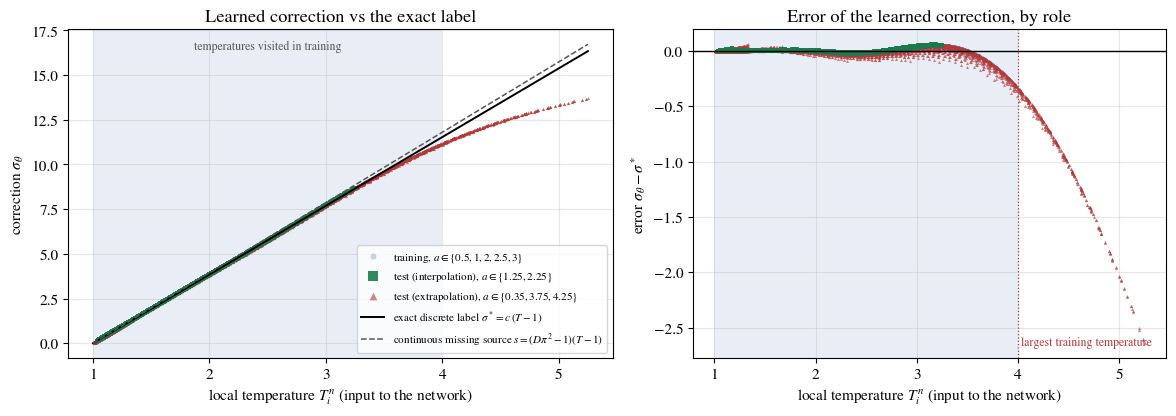

largest temperature in the training trajectories: 4.00
largest temperature in each extrapolation test case: {0.35: 1.35, 3.75: 4.75, 4.25: 5.25}


In [11]:
def node_samples(amps):
    Tn, rh = [], []
    for a in amps:
        P = rollout(a, costa)
        for n in range(N_T):
            Tn.append(P[n][1:-1]); rh.append(costa(P[n], n*dt))
    return np.concatenate(Tn), np.concatenate(rh)

T_hi_train = max(REF[a].max() for a in A_TRAIN)
# for this family r* = c (T_i^n - 1) at every node, because the discrete Laplacian of sin(pi x)
# is a constant multiple of sin(pi x):  c = (e^{-dt} - 1)/dt + D e^{-dt} (2 - 2 cos(pi dx))/dx^2
DISCRETE_SLOPE = (np.exp(-dt) - 1)/dt + D*np.exp(-dt)*(2 - 2*np.cos(np.pi*dx))/dx**2
print(f'slope of the reaction term: continuous {SIGMA_SLOPE:.3f}, exact discrete label {DISCRETE_SLOPE:.3f}')

def plot_costa_heat_mechanism():
    """Left: learned correction against the local temperature, one colour per role, test sets drawn on top.
    Right: the error of the learned correction against the exact discrete label, which is where the roles separate."""
    fig, ax = plt.subplots(1, 2, figsize=(12.0, 4.3), gridspec_kw=dict(width_ratios=[1.15, 1]))
    T_hi_all = max(REF[a].max() for a in A_TEST_EXTRAP)
    roles = [('train', 0.25, 3, 1), ('test_interp', 0.9, 9, 3), ('test_extrap', 0.6, 5, 2)]
    for a_ in ax:
        a_.axvspan(1.0, T_hi_train, color='C0', alpha=0.10, lw=0, zorder=0)
    ax[0].text(0.5*(1 + T_hi_train), 0.97, 'temperatures visited in training', transform=ax[0].get_xaxis_transform(),
               ha='center', va='top', fontsize=8.5, color=muted())
    for role, al, sz, z in roles:
        Tn, rh = node_samples(SPLIT[role]); c, mk = ROLE_STYLE[role]
        lab = f'{ROLE_LABEL[role]}, $a\\in\\{{{", ".join(f"{a:g}" for a in SPLIT[role])}\\}}$'
        ax[0].scatter(Tn, rh, s=sz, alpha=al, color=c, marker=mk, label=lab, zorder=z, lw=0)
        ax[1].scatter(Tn, rh - DISCRETE_SLOPE*(Tn - 1), s=sz, alpha=al, color=c, marker=mk, zorder=z, lw=0)
    Tg = np.linspace(1, T_hi_all, 50)
    ax[0].plot(Tg, DISCRETE_SLOPE*(Tg - 1), '-', color=fg(), lw=1.4, zorder=4,
               label=r'exact discrete label $\sigma^*=c\,(T-1)$')
    ax[0].plot(Tg, SIGMA_SLOPE*(Tg - 1), '--', color=muted(), lw=1.1, zorder=4,
               label=r'continuous missing source $s=(D\pi^2-1)(T-1)$')
    ax[0].set(xlabel='local temperature $T_i^n$ (input to the network)', ylabel=r'correction $\sigma_\theta$',
              title='Learned correction vs the exact label')
    ax[0].legend(fontsize=8, markerscale=2.5, loc='lower right')
    ax[1].axhline(0, color=fg(), lw=1.0, zorder=4)
    ax[1].axvline(T_hi_train, color='C3', lw=0.9, ls=':', zorder=4)
    ax[1].text(T_hi_train, 0.03, ' largest training temperature', transform=ax[1].get_xaxis_transform(),
               ha='left', va='bottom', fontsize=8.5, color='C3')
    ax[1].set(xlabel='local temperature $T_i^n$ (input to the network)',
              ylabel=r'error $\sigma_\theta-\sigma^*$', title='Error of the learned correction, by role')
    plt.tight_layout()

save_dual(plot_costa_heat_mechanism, 'costa_heat_mechanism', FIG)
plt.show()
print(f'largest temperature in the training trajectories: {T_hi_train:.2f}')
print('largest temperature in each extrapolation test case:',
      {a: round(float(REF[a].max()), 2) for a in A_TEST_EXTRAP})

The sweep shows CoSTA's error staying near its in-range level from the smallest amplitudes up to the top of the
training range, then rising steeply. The PBM error grows smoothly with $a$, because the missing source is
proportional to $T-1$ and therefore to $a$.

The mechanism plot explains the rise. Wherever there was training data, the learned correction follows a straight
line in $T$: the exact discrete label, whose slope is a little below the continuous $D\pi^2-1$ because the label also
absorbs the scheme's truncation error. Above the largest training temperature, the large-amplitude test cases ask the network for values it
never saw, and it bends away from the line. This is ordinary function extrapolation in the network's input space.
The relevant question is therefore not "is $a$ new?" but "are the **states** new?" The case $a=0.35$ has a new
amplitude but only familiar states.

This is a narrow generalization experiment: one spatial mode, one decay rate, one grid and one time step. It shows
transfer across amplitudes inside a single manufactured family. It does not show transfer to other initial
shapes, other sources or other discretizations; those would be separate experiments.

## 7. Seeds and features, decided on validation

A single training run is one draw, so we retrain with a declared list of initialization seeds under the same
protocol. We do this for two feature sets:

* `stencil`: $[T_{i-1},T_i,T_{i+1}]$, the default;
* `stencil+xt`: the stencil plus position $x_i$ and time $t_n$, as in earlier versions of this notebook.

Position and time are not needed, since the exact label is a function of the stencil alone. Adding them lets the
network represent corrections that depend on *where* and *when* rather than on the state.

Choosing between the feature sets is a modelling decision, so it is made on the **validation** rollout RMSE. The
test numbers are reported alongside but are not used to choose. One extra declared test condition probes the time
input: the interpolation case `A_SHOW` run for `HORIZON_FACTOR` times the training horizon. That is new territory
for any model that takes $t$ as an input.

In [12]:
HORIZON_FACTOR = 2                                     # long-horizon test: run this many times T_END

def long_rollout(a, corr=None, factor=HORIZON_FACTOR):
    T = Tstar(a, 0.0); traj = [T.copy()]
    for n in range(factor*N_T):
        src = np.zeros(n_int) if corr is None else corr(T, n*dt)
        T = step(T, src); traj.append(T.copy())
    return np.array(traj)

ref_long = np.array([Tstar(A_SHOW, n*dt) for n in range(HORIZON_FACTOR*N_T + 1)])

def test_summary(corr):
    out = {role: {str(a): metrics(rollout(a, corr), REF[a])['rmse'] for a in SPLIT[role]}
           for role in ['test_interp', 'test_extrap']}
    out['long_horizon'] = {str(A_SHOW): metrics(long_rollout(A_SHOW, corr), ref_long)['rmse']}
    return out

TEST_KEYS = [(role, str(a)) for role in ['test_interp', 'test_extrap'] for a in SPLIT[role]] \
            + [('long_horizon', str(A_SHOW))]
kinds = [FEATURES] + ([k for k in ['stencil', 'stencil+xt'] if k != FEATURES] if RUN_ABLATION else [])
seeds = SWEEP_SEEDS if RUN_SEED_SWEEP else [SEED]
sweep = {}
for kind in kinds:
    for s in seeds:
        if kind == FEATURES and s == SEED:
            c_s, i_s = costa, info                       # reuse the walkthrough model
        else:
            c_s, i_s = fit_costa(seed=s, kind=kind)
        sweep[(kind, s)] = dict(best_step=i_s['best_step'], val=i_s['best_val_rollout'], test=test_summary(c_s))

def spread(vals):
    v = np.array(vals); return dict(median=float(np.median(v)), min=float(v.min()), max=float(v.max()),
                                    n_nonfinite=int((~np.isfinite(v)).sum()))

seed_table = {}
for kind in kinds:
    tab = {'validation': spread([sweep[(kind, s)]['val'] for s in seeds])}
    for role, a in TEST_KEYS:
        tab[f'{role} {a}'] = spread([sweep[(kind, s)]['test'][role][a] for s in seeds])
    seed_table[kind] = tab
    print(f"\nfeatures = {kind}: rollout RMSE over seeds {seeds}   (median [min, max])")
    for key, d in tab.items():
        print(f"  {key:22s} {d['median']:.2e}  [{d['min']:.2e}, {d['max']:.2e}]")
    print('  selected checkpoints:', {s: sweep[(kind, s)]['best_step'] for s in seeds})
print(f"\nPBM, long horizon a={A_SHOW}: {metrics(long_rollout(A_SHOW), ref_long)['rmse']:.2e}")
if len(kinds) > 1:
    pick = min(kinds, key=lambda k: seed_table[k]['validation']['median'])
    print(f'validation would choose: {pick}')


features = stencil: rollout RMSE over seeds [0, 1, 2, 3, 4]   (median [min, max])
  validation             7.28e-04  [4.99e-04, 1.03e-03]
  test_interp 1.25       4.32e-04  [2.03e-04, 1.03e-03]
  test_interp 2.25       9.44e-04  [2.25e-04, 1.29e-03]
  test_extrap 0.35       1.14e-03  [3.96e-04, 1.43e-03]
  test_extrap 3.75       3.22e-02  [1.80e-02, 4.00e-02]
  test_extrap 4.25       7.46e-02  [4.98e-02, 8.89e-02]
  long_horizon 2.25      7.33e-04  [4.88e-04, 1.23e-03]
  selected checkpoints: {0: 1000, 1: 1400, 2: 3000, 3: 1600, 4: 3000}

features = stencil+xt: rollout RMSE over seeds [0, 1, 2, 3, 4]   (median [min, max])
  validation             1.26e-03  [7.72e-04, 1.95e-03]
  test_interp 1.25       4.51e-04  [3.28e-04, 1.50e-03]
  test_interp 2.25       4.52e-04  [2.69e-04, 6.80e-04]
  test_extrap 0.35       7.83e-04  [7.47e-04, 2.08e-03]
  test_extrap 3.75       3.91e-02  [2.96e-02, 4.34e-02]
  test_extrap 4.25       9.11e-02  [7.58e-02, 9.94e-02]
  long_horizon 2.25      3.76e-02

Validation prefers the stencil-only features: its median validation rollout RMSE is lower, so `stencil` stays the
default. Seen through the test cases, the two feature sets are comparable inside the training horizon. Neither is
reliably better, and the seed-to-seed range (often a factor of two to five) is as large as the difference
between them.

The long-horizon case separates them. Run to twice the training horizon, the stencil-only model keeps its in-range
accuracy, because nothing it sees is new. The model that also takes $t$ is fed times it never saw, and its error
grows by more than an order of magnitude. A state-only correction is also *autonomous*, which is the assumption
the error analysis in the chapter makes.

Across seeds every rollout stays finite, and the ordering in-range < large-amplitude holds for every seed. Read any
single-run number in this notebook with that factor-of-several spread in mind.

In [13]:
results = dict(
    config={k: globals()[k] for k in DEFAULTS} | dict(RUN_ABLATION=RUN_ABLATION, SWEEP_SEEDS=SWEEP_SEEDS,
                                                       HORIZON_FACTOR=HORIZON_FACTOR),
    manifest=MANIFEST, selected=dict(best_step=info['best_step'], stopped_at=info['stopped_at'],
                                     best_val_rollout_rmse=info['best_val_rollout']),
    metrics=rows, seed_and_feature_sweep=seed_table)
with open(RESULTS_FILE, 'w') as fh:
    json.dump(results, fh, indent=1)
print('saved', os.path.relpath(RESULTS_FILE))

if AT_DEFAULTS:
    t_int = [rw for rw in rows if rw['role'] == 'test_interp']
    assert all(rw['costa']['rmse'] < 0.01*rw['pbm']['rmse'] for rw in t_int)
else:
    print('regression check skipped (non-default parameters)')

saved ../data/costa_heat_results.json


**Summary.**

* CoSTA learns the correction that the PBM's own discrete step needs. Labels come from consecutive reference states;
  predictions use only the current, model-generated state.
* Training fits that correction on the training trajectories. Validation rollouts select the checkpoint. Testing
  runs the frozen model recursively on held-out amplitudes.
* Inside the training state range the corrected solver is accurate to about $10^{-3}$ in rollout RMSE. Beyond it,
  accuracy degrades in the way the mechanism plot predicts.
* A zero correction reproduces the PBM exactly. That is an identity, not a guarantee: it says nothing about
  stability or accuracy when the correction is nonzero, which must be checked as here.
* The learned correction approximates the reaction term $(D\pi^2-1)(T-1)$. Regressing a symbolic form onto it
  leads to equation discovery (Module 21).